<div style="background:#080c10;padding:22px 26px;border-radius:10px;border-left:4px solid #00d4ff">
<h1 style="color:#00d4ff;margin:0 0 8px 0">NBA Opening &amp; Closing Odds, World Books — Verify before you buy</h1>
<p style="color:#e6edf3;margin:0;font-size:15px">The figures of the listing and of its README, recomputed from the file of the
full product: 23,212 NBA games from the 2008-09 season to 31 October 2026, opening and closing prices from Pinnacle, Bet365,
William Hill, Bwin, Betway, Betfair Exchange, SBOBET and 1xBet, in decimal odds, each with the time it was recorded.</p>
</div>

This notebook runs on the **full product**, not on the sample. Each section states a claim of the listing or of the
README, recomputes it from the file and prints **PASS** or **FAIL**. The expected values are written in plain sight:
the README's and the listing's in the `CLAIMS` cell, the images' next to their check; everything else is read from the
data. Only what the file cannot show is not recomputed: the counts of prices left out while it was built (2,363
closing prices too far from the market and the others listed in the README), the 8 corrected tip-off times and the 145
Pinnacle closes taken from a second record.

🏀 **[→ The full dataset on Gumroad](https://sportsdataolivier.gumroad.com/l/oeuoto?utm_source=github&utm_medium=notebook&utm_campaign=nba_world&utm_content=notebook_top)** · also on [Whop](https://whop.com/oliviersportsdata/nba-opening-closing-odds-pinnacle-7-world-books-2008-2026/?utm_source=github&utm_medium=notebook&utm_campaign=nba_world&utm_content=whop_top) · free 20-game sample: same layout, same 182 columns.

## 0 · Setup

In [1]:
import os, glob, math, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

def find_csv():
    """The CSV of the full product: the largest NBA_World_Opening_Closing_Odds file wins (sample and full may both be attached)."""
    hits = []
    for base in (os.environ.get("NBA_ROOT", ""), "/kaggle/input", "."):
        if base and os.path.isdir(base):
            hits += [p for p in glob.glob(os.path.join(base, "**", "NBA_World_Opening_Closing_Odds_2008-2026*.csv"), recursive=True)
                     if os.path.isfile(p)]
    if not hits:
        raise FileNotFoundError("NBA_World_Opening_Closing_Odds_2008-2026.csv not found: attach the dataset to this notebook")
    return max(hits, key=os.path.getsize)

PATH = find_csv()
RAW = pd.read_csv(PATH, dtype=str)                 # every cell exactly as written in the file
F = pd.read_csv(PATH, low_memory=False)            # the same file, numbers parsed
print(f"{os.path.basename(PATH)}  ·  {os.path.getsize(PATH) / 1e6:.1f} MB  ·  {len(F):,} rows  ·  {F.shape[1]} columns")

BOOKS = ["Pinnacle", "Bet365", "WilliamHill", "Bwin", "Betway", "BetfairExchange", "SBOBET", "1xBet"]
NAME = {"WilliamHill": "William Hill", "BetfairExchange": "Betfair Exchange"}
ODDS = list(F.columns[14:])
PRICES = [c for c in ODDS if not c.endswith("_Time") and "_Line_" not in c]
LINES = [c for c in ODDS if "_Line_" in c]
KICK = pd.to_datetime(F["Kickoff_UTC"], utc=True)
RESTART = pd.Timestamp("2020-07-30", tz="UTC")     # the NBA restarted in the Orlando bubble on 30 July 2020
SEASONS = sorted(F["Season"].unique())

def ts(col):
    return pd.to_datetime(F[col], utc=True)

def minutes_vs_tipoff(col):
    """Minutes between the recorded time and the scheduled tip-off: negative = before."""
    return (ts(col) - KICK).dt.total_seconds() / 60

def no_vig(home, away):
    """Implied probability of the home team from two decimal prices, margin removed proportionally."""
    h, a = 1 / np.asarray(home, float), 1 / np.asarray(away, float)
    return h / (h + a)

def time_of(price_col):
    """The time column of a price column: Bwin_ML_Home_Close -> Bwin_ML_Close_Time."""
    p = price_col.split("_")
    return f"{p[0]}_{p[1]}_{p[-1]}_Time"

def share(n, d):
    """Share in %, rounded down, written as in the README ('–' = none)."""
    return "–" if n == 0 else str(int(100 * n / d))

def short_age(m):
    """A median in minutes, written as in the README's closing-time table."""
    m = round(m)
    if m == 0:
        return "at tip-off"
    side = "after" if m > 0 else "before"
    return f"{abs(m)} min {side}" if abs(m) < 120 else f"{abs(m) / 60:.1f} h {side}"

RESULTS = []
def check(claim, ok, detail=""):
    ok = bool(ok)
    RESULTS.append((claim, ok, detail))
    print(f"{'PASS' if ok else 'FAIL'}  {claim}" + (f"   [{detail}]" if detail else ""))

# Olivier Sports Data dark signature
BG, FG, FG2, GRID, CYAN, AMBER = "#080c10", "#e6edf3", "#9aa7b2", "#1c2630", "#00d4ff", "#f5c86b"
plt.rcParams.update({"figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG, "text.color": FG,
                     "axes.labelcolor": FG, "axes.edgecolor": GRID, "xtick.color": FG2, "ytick.color": FG2,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.titlecolor": FG,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "font.size": 10, "legend.frameon": False})

NBA_World_Opening_Closing_Odds_2008-2026.csv  ·  24.3 MB  ·  23,212 rows  ·  182 columns


## 1 · The claims

Copied from the listing and the README shipped in the ZIP. Nothing below is adjusted to fit: if the file
disagrees, the cell prints FAIL.

In [2]:
def table(text, cols):
    """A table copied from the README: one row per season, '–' = none."""
    out = {}
    for line in text.strip().splitlines():
        cells = [c.strip() for c in line.strip().strip("|").split("|")]
        out[cells[0]] = dict(zip(cols, cells[1:]))
    return out

SIX = ["Pinnacle", "Bet365", "Bwin", "Betway", "SBOBET", "1xBet"]
CLAIMS = {
    "games": 23_212, "seasons": 19, "columns": 182, "books": 8, "prices": 1_203_088, "overtime": 1_323,
    "last_game_date": "20261031", "games_2026_27": 88,
    "per_stage": {"Regular Season": 21_666, "Playoffs": 1_506, "Play-In": 37, "NBA Cup Final": 3},
    "columns_per_book": {"Pinnacle": 22, "Bet365": 22, "WilliamHill": 6, "Bwin": 30, "Betway": 30,
                         "BetfairExchange": 6, "SBOBET": 22, "1xBet": 30},
    "markets": {"Pinnacle": "ML Spread Total", "Bet365": "ML Spread Total", "WilliamHill": "ML", "Bwin": "ML Spread Total 1X2",
                "Betway": "ML Spread Total 1X2", "BetfairExchange": "ML", "SBOBET": "ML Spread Total", "1xBet": "ML Spread Total 1X2"},
    # listing and README: first game with a price, book by book (the date of the Game_ID, US Eastern)
    "first_price": {"Bet365": "20090119", "Bwin": "20090129", "Betway": "20090129", "BetfairExchange": "20090211",
                    "WilliamHill": "20100603", "SBOBET": "20110307", "1xBet": "20141028", "Pinnacle": "20181016"},
    "first_price_market": {"Pinnacle Spread": "20200730", "SBOBET ML": "20190422", "1xBet 1X2": "20141028",
                           "1xBet Spread": "20150102", "1xBet ML": "20151031"},
    # README, said plainly
    "no_price_games": {"2008/2009": 602, "2010/2011": 21}, "no_price_last_2008_09": "20090219",
    "no_price_17_jan_2011": (8, 13),
    "corrected_score": ("20251107_CLE_WAS", 148, 115),
    "william_hill_back": "20260401",
    "nba_cup_knockout_dates": ["20231204", "20231205", "20231207", "20231209", "20241210", "20241211", "20241214",
                               "20241217", "20251209", "20251210", "20251213", "20251216"],
    "nba_cup_knockout_games": 21,
    "betfair_1xbet_games_2026_27": 4,
    "bet365_thin_openings": {"spread": (5, 29), "total_under": 6},          # % of games, 2015-16 to 2025-26
    "pinnacle_close_before_restart_h": {"2018/2019": 5.4, "2019/2020": 5.1},
    "pinnacle_close_from_restart_min": 9,
    "median_open_age_h": {"Pinnacle": 21, "Bet365": 17, "WilliamHill": 19, "Bwin": 24, "Betway": 20,
                          "BetfairExchange": 23, "SBOBET": 18, "1xBet": 27},
    "oldest_opening_days": 14, "oldest_close_hours": 12, "latest_close_minutes": 30,
    "seconds": {"Betway 2026-27 %": 65, "WilliamHill cells": 8},
    "margin_close_median": {"BetfairExchange": 2.8, "Pinnacle": 2.6},
    # README: prices that cannot exist were not used
    "limits": {"min_price": 1.01, "margin": (1, 12), "margin_exchange": (0, 6), "margin_1x2": (2, 20),
               "spread_total_prices": (1.40, 3.50), "total_line": (150, 290), "spread_line_max": 30},
    "first_month": "200810",
    # README, games: the bubble, the short seasons, the cancelled game, the team names
    "bubble_seeding_games": 88,
    "games_per_team": {"2011/2012": 66, "2020/2021": 72},
    "cancelled_2012_13": ("Indiana Pacers", "Boston Celtics", 81),     # Indiana at Boston: both teams 81 games, every other team 82
    "nba_cup_rounds_in_regular_season": 18,                            # quarter-finals and semi-finals, 2023-24 to 2025-26
    "match_endings": {"Regular Time": 21_889, "Overtime": 1_323},
    "names": {"NJN": ("New Jersey Nets", "2011/2012"), "BKN": ("Brooklyn Nets", "2012/2013"),
              "NOH": ("New Orleans Hornets", "2012/2013"), "NOP": ("New Orleans Pelicans", "2013/2014"),
              "CHA": (("Charlotte Bobcats", "2013/2014"), ("Charlotte Hornets", "2014/2015"))},
    # listing FAQ: before 2018-19, each season carries 4 to 7 of the other books (all 7 from 2015-16)
    "books_before_pinnacle": {"2008/2009": 4, "2009/2010": 5, "2010/2011": 6, "2011/2012": 6, "2012/2013": 6,
                              "2013/2014": 6, "2014/2015": 6, "2015/2016": 7, "2016/2017": 7, "2017/2018": 7},
    "first_1x2_season": {"Bwin": "2013/2014", "1xBet": "2014/2015", "Betway": "2016/2017"},
    "sbobet_seasons": {"Spread": ("2010/2011", "2021/2022"), "Total": ("2010/2011", "2021/2022"), "ML": ("2018/2019", "2021/2022")},
    # README, said plainly: Betway's spread, total and 1X2, and Bwin's thin openings
    "betway": {"spread_total_from": "20110331", "no_spread": ("20160701", "20240930"), "neither": ("20241207", "20261019"),
               "x12_runs": [("20161025", "20220206"), ("20241207", "20251211"), ("20261020", "20261024")], "x12_games_2026_27": 35},
    "bwin_thin_openings": {"spread": (3, 7), "total_under": 5},           # % of games, 2008-09 to 2013-14
}
CLAIMS["games_table"] = table("""
| 2008/2009 | 1,230 | – | 85 | – | 1,315 |
| 2009/2010 | 1,230 | – | 82 | – | 1,312 |
| 2010/2011 | 1,230 | – | 81 | – | 1,311 |
| 2011/2012 | 990 | – | 84 | – | 1,074 |
| 2012/2013 | 1,229 | – | 85 | – | 1,314 |
| 2013/2014 | 1,230 | – | 89 | – | 1,319 |
| 2014/2015 | 1,230 | – | 81 | – | 1,311 |
| 2015/2016 | 1,230 | – | 86 | – | 1,316 |
| 2016/2017 | 1,230 | – | 79 | – | 1,309 |
| 2017/2018 | 1,230 | – | 82 | – | 1,312 |
| 2018/2019 | 1,230 | – | 82 | – | 1,312 |
| 2019/2020 | 1,059 | 1 | 83 | – | 1,143 |
| 2020/2021 | 1,080 | 6 | 85 | – | 1,171 |
| 2021/2022 | 1,230 | 6 | 87 | – | 1,323 |
| 2022/2023 | 1,230 | 6 | 84 | – | 1,320 |
| 2023/2024 | 1,230 | 6 | 82 | 1 | 1,319 |
| 2024/2025 | 1,230 | 6 | 84 | 1 | 1,321 |
| 2025/2026 | 1,230 | 6 | 85 | 1 | 1,322 |
| 2026/2027 | 88 | – | – | – | 88 |
""", ["Regular Season", "Play-In", "Playoffs", "NBA Cup Final", "Total"])
CLAIMS["median_close"] = table("""
| Pinnacle | 8 min after | 9 min after | 8 min after | – |
| Bet365 | 45 min before | 71 min before | 92 min before | – |
| WilliamHill | 69 min before | – | – | – |
| Bwin | 53 min before | 71 min before | 65 min before | 45 min before |
| Betway | 36 min before | 2.1 h before | 53 min before | 15 min before |
| BetfairExchange | 4 min before | – | – | – |
| SBOBET | 18 min before | 5 min before | 12 min before | – |
| 1xBet | 27 min before | 31 min before | 28 min before | 28 min before |
""", ["ML", "Spread", "Total", "1X2"])
CLAIMS["coverage"] = {
    ("ML_Home_Close", "Closing moneyline"): table("""
| 2008/2009 | – | 50 | – | 34 | 36 | 14 | – | – |
| 2009/2010 | – | 98 | 0 | 86 | 93 | 96 | – | – |
| 2010/2011 | – | 96 | 91 | 87 | 95 | 95 | – | – |
| 2011/2012 | – | 96 | 95 | 91 | 97 | 98 | – | – |
| 2012/2013 | – | 99 | 87 | 77 | 92 | 99 | – | – |
| 2013/2014 | – | 99 | 89 | 94 | 95 | 99 | – | – |
| 2014/2015 | – | 98 | 97 | 99 | 96 | – | – | – |
| 2015/2016 | – | 98 | 97 | 98 | 96 | 28 | – | 81 |
| 2016/2017 | – | 99 | 98 | 99 | 99 | 99 | – | 97 |
| 2017/2018 | – | 99 | 96 | 98 | 98 | 70 | – | 98 |
| 2018/2019 | 95 | 98 | 97 | 96 | 98 | 99 | 3 | 99 |
| 2019/2020 | 93 | 99 | 98 | 94 | 99 | 99 | 98 | 95 |
| 2020/2021 | 99 | 99 | 99 | 95 | 99 | 98 | 98 | 81 |
| 2021/2022 | 99 | 98 | 95 | 85 | 99 | 91 | 64 | 98 |
| 2022/2023 | 99 | 97 | 96 | 95 | 99 | 97 | – | 96 |
| 2023/2024 | 100 | 97 | 95 | 98 | 99 | 99 | – | 96 |
| 2024/2025 | 99 | 99 | 94 | 98 | 95 | 99 | – | 99 |
| 2025/2026 | 100 | 96 | 11 | 98 | 96 | 89 | – | 88 |
| 2026/2027 | 100 | 100 | 86 | 98 | 96 | 4 | – | 4 |
""", BOOKS),
    ("ML_Home_Open", "Opening moneyline"): table("""
| 2008/2009 | – | 26 | – | 21 | 20 | 10 | – | – |
| 2009/2010 | – | 72 | 0 | 79 | 62 | 27 | – | – |
| 2010/2011 | – | 76 | 70 | 81 | 61 | 0 | – | – |
| 2011/2012 | – | 77 | 54 | 87 | 62 | – | – | – |
| 2012/2013 | – | 80 | 59 | 77 | 63 | 0 | – | – |
| 2013/2014 | – | 82 | 72 | 89 | 80 | 0 | – | – |
| 2014/2015 | – | 84 | 80 | 82 | 81 | – | – | – |
| 2015/2016 | – | 87 | 81 | 87 | 85 | 2 | – | 74 |
| 2016/2017 | – | 91 | 84 | 82 | 88 | 6 | – | 92 |
| 2017/2018 | – | 89 | 83 | 73 | 88 | 7 | – | 90 |
| 2018/2019 | 99 | 89 | 78 | 81 | 86 | 7 | 3 | 91 |
| 2019/2020 | 97 | 90 | 84 | 82 | 87 | 10 | 89 | 85 |
| 2020/2021 | 99 | 90 | 88 | 86 | 88 | 2 | 92 | 78 |
| 2021/2022 | 99 | 83 | 67 | 75 | 78 | 3 | 60 | 90 |
| 2022/2023 | 100 | 85 | 86 | 86 | 81 | 9 | – | 91 |
| 2023/2024 | 100 | 88 | 84 | 85 | 77 | 4 | – | 87 |
| 2024/2025 | 99 | 71 | 86 | 86 | 76 | 39 | – | 90 |
| 2025/2026 | 99 | 87 | 11 | 85 | 75 | 16 | – | 83 |
| 2026/2027 | 100 | 65 | 84 | 64 | 70 | – | – | 4 |
""", BOOKS),
    ("Spread_Home_Close", "Closing spread"): table("""
| 2008/2009 | – | 50 | 34 | – | – | – |
| 2009/2010 | – | 87 | 82 | – | – | – |
| 2010/2011 | – | 85 | 75 | 10 | 27 | – |
| 2011/2012 | – | 90 | 81 | 87 | 99 | – |
| 2012/2013 | – | 94 | 50 | 85 | 98 | – |
| 2013/2014 | – | 95 | 81 | 95 | 98 | – |
| 2014/2015 | – | 96 | 97 | 96 | 98 | 0 |
| 2015/2016 | – | 96 | 96 | 97 | 98 | 81 |
| 2016/2017 | – | 97 | 97 | – | 97 | 99 |
| 2017/2018 | – | 86 | 97 | – | 98 | 99 |
| 2018/2019 | – | 94 | 97 | – | 96 | 99 |
| 2019/2020 | 12 | 95 | 92 | – | 98 | 95 |
| 2020/2021 | 97 | 96 | 94 | – | 97 | 96 |
| 2021/2022 | 98 | 90 | 87 | – | 64 | 97 |
| 2022/2023 | 98 | 88 | 97 | – | – | 95 |
| 2023/2024 | 98 | 90 | 98 | – | – | 97 |
| 2024/2025 | 98 | 96 | 97 | 24 | – | 97 |
| 2025/2026 | 99 | 92 | 98 | – | – | 88 |
| 2026/2027 | 100 | 98 | 100 | 100 | – | 4 |
""", SIX),
    ("Total_Over_Close", "Closing total"): table("""
| 2008/2009 | – | 50 | 36 | – | – | – |
| 2009/2010 | – | 93 | 87 | – | – | – |
| 2010/2011 | – | 93 | 89 | 11 | 27 | – |
| 2011/2012 | – | 97 | 94 | 95 | 97 | – |
| 2012/2013 | – | 98 | 78 | 91 | 96 | – |
| 2013/2014 | – | 98 | 94 | 97 | 95 | – |
| 2014/2015 | – | 99 | 96 | 98 | 96 | 0 |
| 2015/2016 | – | 97 | 98 | 99 | 96 | 81 |
| 2016/2017 | – | 97 | 98 | 99 | 95 | 99 |
| 2017/2018 | – | 87 | 99 | 98 | 96 | 99 |
| 2018/2019 | 97 | 97 | 98 | 97 | 95 | 99 |
| 2019/2020 | 93 | 97 | 96 | 99 | 91 | 95 |
| 2020/2021 | 99 | 95 | 98 | 99 | 91 | 94 |
| 2021/2022 | 99 | 95 | 89 | 99 | 59 | 98 |
| 2022/2023 | 99 | 89 | 98 | 98 | – | 98 |
| 2023/2024 | 99 | 88 | 99 | 97 | – | 98 |
| 2024/2025 | 99 | 98 | 98 | 24 | – | 98 |
| 2025/2026 | 99 | 89 | 98 | – | – | 88 |
| 2026/2027 | 100 | 100 | 100 | 100 | – | 4 |
""", SIX),
    ("1X2_Home_Close", "Closing 1X2"): table("""
| 2008/2009 | – | – | – |
| 2009/2010 | – | – | – |
| 2010/2011 | – | – | – |
| 2011/2012 | – | – | – |
| 2012/2013 | – | – | – |
| 2013/2014 | 38 | – | – |
| 2014/2015 | 99 | – | 98 |
| 2015/2016 | 98 | – | 98 |
| 2016/2017 | 99 | 99 | 98 |
| 2017/2018 | 99 | 99 | 99 |
| 2018/2019 | 73 | 99 | 99 |
| 2019/2020 | 95 | 99 | 30 |
| 2020/2021 | 91 | 99 | 89 |
| 2021/2022 | 86 | 60 | 92 |
| 2022/2023 | 97 | – | 97 |
| 2023/2024 | 99 | – | 96 |
| 2024/2025 | 99 | 71 | 99 |
| 2025/2026 | 96 | 26 | 41 |
| 2026/2027 | 100 | 37 | 4 |
""", ["Bwin", "Betway", "1xBet"]),
    ("Spread_Home_Open", "Opening spread"): table("""
| 2008/2009 | – | 10 | 3 | – | – | – |
| 2009/2010 | – | 8 | 6 | – | – | – |
| 2010/2011 | – | 28 | 3 | 1 | 25 | – |
| 2011/2012 | – | 71 | 7 | 11 | 91 | – |
| 2012/2013 | – | 76 | 4 | 11 | 88 | – |
| 2013/2014 | – | 76 | 4 | 62 | 93 | – |
| 2014/2015 | – | 71 | 25 | 78 | 91 | – |
| 2015/2016 | – | 17 | 21 | 82 | 91 | 73 |
| 2016/2017 | – | 15 | 42 | – | 88 | 92 |
| 2017/2018 | – | 12 | 72 | – | 89 | 83 |
| 2018/2019 | – | 21 | 82 | – | 88 | 94 |
| 2019/2020 | 11 | 24 | 80 | – | 92 | 85 |
| 2020/2021 | 98 | 29 | 82 | – | 89 | 82 |
| 2021/2022 | 99 | 12 | 60 | – | 59 | 82 |
| 2022/2023 | 99 | 5 | 81 | – | – | 78 |
| 2023/2024 | 99 | 14 | 81 | – | – | 80 |
| 2024/2025 | 99 | 19 | 88 | 16 | – | 81 |
| 2025/2026 | 99 | 28 | 89 | – | – | 78 |
| 2026/2027 | 100 | 71 | 76 | 100 | – | 4 |
""", SIX),
    ("Total_Over_Open", "Opening total"): table("""
| 2008/2009 | – | 0 | 1 | – | – | – |
| 2009/2010 | – | 0 | 1 | – | – | – |
| 2010/2011 | – | 27 | 0 | 0 | 24 | – |
| 2011/2012 | – | 86 | 4 | 1 | 87 | – |
| 2012/2013 | – | 89 | 2 | 0 | 84 | – |
| 2013/2014 | – | 89 | 1 | 16 | 85 | – |
| 2014/2015 | – | 76 | 14 | 24 | 84 | – |
| 2015/2016 | – | 0 | 11 | 14 | 86 | 72 |
| 2016/2017 | – | 0 | 45 | 53 | 84 | 89 |
| 2017/2018 | – | 0 | 78 | 52 | 84 | 85 |
| 2018/2019 | 99 | 0 | 81 | 44 | 83 | 92 |
| 2019/2020 | 97 | 2 | 83 | 60 | 77 | 88 |
| 2020/2021 | 99 | 1 | 88 | 69 | 73 | 86 |
| 2021/2022 | 100 | 5 | 73 | 63 | 43 | 81 |
| 2022/2023 | 99 | – | 83 | 61 | – | 81 |
| 2023/2024 | 100 | 0 | 82 | 28 | – | 79 |
| 2024/2025 | 99 | 3 | 83 | 13 | – | 74 |
| 2025/2026 | 99 | 1 | 87 | – | – | 75 |
| 2026/2027 | 100 | 75 | 82 | 100 | – | 3 |
""", SIX),
}
print(f"{sum(len(v) for v in CLAIMS['coverage'].values())} coverage rows, {len(CLAIMS)} claims blocks, copied from the README")

133 coverage rows, 46 claims blocks, copied from the README


## 2 · The file

One CSV, one row per game. For each book and market: the opening price, then the closing price, each with the time
it was recorded. Decimal odds.

In [3]:
check(f"{CLAIMS['games']:,} games, Game_ID unique", len(F) == CLAIMS["games"] and F["Game_ID"].is_unique, f"{len(F):,}")
check(f"{CLAIMS['columns']} columns: 14 for the game, then the books", F.shape[1] == CLAIMS["columns"] and len(ODDS) == CLAIMS["columns"] - 14,
      f"{F.shape[1]}")
found = list(dict.fromkeys(c.split("_")[0] for c in ODDS))
check(f"{CLAIMS['books']} books, in this order: " + ", ".join(NAME.get(b, b) for b in BOOKS), found == BOOKS, ", ".join(found))
order_ok = all(max(i for i, c in enumerate(ODDS) if c.startswith(b + "_") and "_Open" in c)
               < min(i for i, c in enumerate(ODDS) if c.startswith(b + "_") and "_Close" in c) for b in BOOKS)
check("for each book, its opening columns come first, then its closing columns", order_ok)
per = {b: sum(c.startswith(b + "_") for c in ODDS) for b in BOOKS}
check("columns per book: 22, 6 for William Hill and Betfair Exchange, 30 with the 1X2", per == CLAIMS["columns_per_book"],
      " · ".join(f"{NAME.get(b, b)} {n}" for b, n in per.items()))
mk = {b: " ".join(dict.fromkeys(c.split("_")[1] for c in ODDS if c.startswith(b + "_"))) for b in BOOKS}
check("markets per book, as listed (William Hill and Betfair Exchange: moneyline only)", mk == CLAIMS["markets"])
cells = pd.Series(RAW[PRICES].to_numpy().ravel()).dropna()
check(f"{CLAIMS['prices']:,} prices", len(cells) == CLAIMS["prices"], f"{len(cells):,}")
check(f"every price is a decimal price of at least {CLAIMS['limits']['min_price']}, with up to 4 decimals",
      cells.str.fullmatch(r"\d+(\.\d{1,4})?").all() and (cells.astype(float) >= CLAIMS["limits"]["min_price"]).all(),
      f"lowest {cells.astype(float).min()}, highest {cells.astype(float).max()}")
untimed = sum(int((F[c].notna() & F[time_of(c)].isna()).sum()) for c in PRICES)
check("every price comes with the time it was recorded", untimed == 0, f"{untimed} without a time")
times = pd.Series(RAW[[c for c in ODDS if c.endswith("_Time")] + ["Kickoff_UTC"]].to_numpy().ravel()).dropna()
check("every time is ISO 8601 in UTC, with the T and the Z", times.str.fullmatch(r"\d{4}-\d\d-\d\dT\d\d:\d\d:\d\dZ").all(),
      f"{len(times):,} cells")
check("Epoch is the scheduled tip-off in Unix seconds", (pd.to_datetime(F["Epoch"], unit="s", utc=True) == KICK).all())
away_code, home_code = F["Game_ID"].str[9:12], F["Game_ID"].str[13:16]
codes = pd.concat([pd.DataFrame({"Season": F["Season"], "Team": F["Home_Team"], "Code": home_code}),
                   pd.DataFrame({"Season": F["Season"], "Team": F["Away_Team"], "Code": away_code})])
one_code = codes.groupby(["Season", "Team"])["Code"].nunique().max() == 1
check("Game_ID reads YYYYMMDD_AWAY_HOME: the date in US Eastern time, then the away team's code, then the home team's",
      RAW["Game_ID"].str.fullmatch(r"\d{8}_[A-Z]{3}_[A-Z]{3}").all() and one_code
      and (KICK.dt.tz_convert("America/New_York").dt.strftime("%Y%m%d") == F["Game_ID"].str[:8]).all())

PASS  23,212 games, Game_ID unique   [23,212]
PASS  182 columns: 14 for the game, then the books   [182]
PASS  8 books, in this order: Pinnacle, Bet365, William Hill, Bwin, Betway, Betfair Exchange, SBOBET, 1xBet   [Pinnacle, Bet365, WilliamHill, Bwin, Betway, BetfairExchange, SBOBET, 1xBet]
PASS  for each book, its opening columns come first, then its closing columns
PASS  columns per book: 22, 6 for William Hill and Betfair Exchange, 30 with the 1X2   [Pinnacle 22 · Bet365 22 · William Hill 6 · Bwin 30 · Betway 30 · Betfair Exchange 6 · SBOBET 22 · 1xBet 30]
PASS  markets per book, as listed (William Hill and Betfair Exchange: moneyline only)


PASS  1,203,088 prices   [1,203,088]


PASS  every price is a decimal price of at least 1.01, with up to 4 decimals   [lowest 1.01, highest 76.0]
PASS  every price comes with the time it was recorded   [0 without a time]


PASS  every time is ISO 8601 in UTC, with the T and the Z   [595,666 cells]
PASS  Epoch is the scheduled tip-off in Unix seconds


PASS  Game_ID reads YYYYMMDD_AWAY_HOME: the date in US Eastern time, then the away team's code, then the home team's


### Prices that cannot exist

The README lists the prices that were not used: margins out of bounds, lines that are not a multiple of 0.25,
spread and total prices outside 1.40-3.50. Recomputed on every price left in the file.

In [4]:
L = CLAIMS["limits"]
def values(cols):
    """Every non-empty cell of these columns, as one series."""
    return pd.Series(F[cols].to_numpy().ravel()).dropna()
lines = values(LINES)
spread_l = values([c for c in LINES if "_Spread_" in c])
total_l = values([c for c in LINES if "_Total_" in c])
check("every spread and total line is a multiple of 0.25", ((lines * 4) % 1 == 0).all(), f"{len(lines):,} lines")
check(f"total lines between {L['total_line'][0]} and {L['total_line'][1]} points, spread lines within {L['spread_line_max']} points",
      total_l.between(*L["total_line"]).all() and (spread_l.abs() <= L["spread_line_max"]).all(),
      f"totals {total_l.min()} to {total_l.max()} · spreads {spread_l.min()} to {spread_l.max()}")
sp_to = values([c for c in PRICES if "_Spread_" in c or "_Total_" in c])
check(f"spread and total prices between {L['spread_total_prices'][0]:.2f} and {L['spread_total_prices'][1]:.2f}",
      sp_to.between(*L["spread_total_prices"]).all(), f"{sp_to.min()} to {sp_to.max()}")

def margins(book, market, phase):
    if market == "1X2":
        cols = [f"{book}_1X2_{s}_{phase}" for s in ("Home", "Draw", "Away")]
    elif market == "ML":
        cols = [f"{book}_ML_Home_{phase}", f"{book}_ML_Away_{phase}"]
    elif market == "Spread":
        cols = [f"{book}_Spread_Home_{phase}", f"{book}_Spread_Away_{phase}"]
    else:
        cols = [f"{book}_Total_Over_{phase}", f"{book}_Total_Under_{phase}"]
    if cols[0] not in F:
        return pd.Series(dtype=float)
    x = F[cols].dropna()
    return 100 * ((1 / x).sum(axis=1) - 1)

bad, rows = [], []
for b in BOOKS:
    for m in ("ML", "Spread", "Total", "1X2"):
        for ph in ("Open", "Close"):
            mg = margins(b, m, ph)
            if mg.empty:
                continue
            lo, hi = L["margin_1x2"] if m == "1X2" else (L["margin_exchange"] if b == "BetfairExchange" else L["margin"])
            out = int((~mg.between(lo, hi)).sum())
            rows.append((NAME.get(b, b), m, ph, len(mg), round(mg.min(), 2), round(mg.median(), 2), round(mg.max(), 2)))
            if out:
                bad.append(f"{b} {m} {ph}: {out}")
check("every two-way market has a margin of 1-12% (Betfair Exchange 0-6%), every 1X2 2-20%", not bad, ", ".join(bad[:6]))
pd.DataFrame(rows, columns=["Book", "Market", "Phase", "Markets", "Min %", "Median %", "Max %"]).set_index(["Book", "Market", "Phase"])

PASS  every spread and total line is a multiple of 0.25   [287,908 lines]
PASS  total lines between 150 and 290 points, spread lines within 30 points   [totals 169.0 to 264.5 · spreads -25.5 to 21.5]
PASS  spread and total prices between 1.40 and 3.50   [1.46 to 2.65]
PASS  every two-way market has a margin of 1-12% (Betfair Exchange 0-6%), every 1X2 2-20%


Markets  Min %  Median %  Max %
Book             Market Phase                                 
Pinnacle         ML     Open     10280   2.11      2.78   5.20
                        Close    10174   1.71      2.65   7.02
                 Spread Open      7962   2.19      2.44   4.13
                        Close     7887   1.92      2.44   6.96
                 Total  Open     10284   2.29      2.91   4.52
                        Close    10184   2.29      2.91   6.97
Bet365           ML     Open     18723   1.04      4.26  10.73
                        Close    22228   1.12      4.26  11.64
                 Spread Open      7007   4.34      5.26   9.76
                        Close    20985   3.76      5.26  10.10
                 Total  Open      4948   4.34      5.26   8.70
                        Close    21460   4.71      5.26   9.29
William Hill     ML     Open     15136   1.93      3.98  10.33
                        Close    18519   1.55      3.93   8.50
Bwin             ML     Open     18454   1.05      4.60  11.74
                        Close    21006   1.18      4.60  10.12
                 Spread Open     10808   2.04      4.71  10.23
                        Close    20145   2.04      4.71  11.79
                 Total  Open     10678   2.04      4.71  10.23
                        Close    21315   2.04      4.71  11.79
                 1X2    Open      7554   7.06     10.53  15.28
                        Close    15251   6.99     10.77  16.52
Betway           ML     Open     17374   1.05      4.44  10.90
                        Close    21795   1.05      4.57  10.12
                 Spread Open      3530   3.60      4.71   8.11
                        Close     6427   3.60      4.71   8.19
                 Total  Open      6517   3.60      4.76   9.29
                        Close    16758   3.60      4.71   9.29
                 1X2    Open      4656   3.05      8.23  12.73
                        Close     8349   2.44      8.27  12.27
Betfair Exchange ML     Open      1933   0.01      2.87   5.99
                        Close    18923   0.32      2.82   5.99
SBOBET           ML     Open      2962   2.56      5.67  11.97
                        Close     3182   2.56      5.73  11.62
                 Spread Open     12484   2.32      3.09   4.90
                        Close    13544   2.06      2.61   4.49
                 Total  Open     11358   3.09      3.63   4.97
                        Close    13136   3.02      3.32   5.49
1xBet            ML     Open     12338   1.09      3.43   9.75
                        Close    13339   1.00      1.84   9.56
                 Spread Open     11760   1.27      4.71  10.85
                        Close    13498   1.27      2.05  11.11
                 Total  Open     11659   1.27      4.71  11.89
                        Close    13574   1.01      2.04   9.50
                 1X2    Open      8816   3.26      5.88  12.32
                        Close    13554   3.06      4.56  17.69

## 3 · Games

In [5]:
st = pd.crosstab(F["Season"], F["Stage"]).reindex(columns=["Regular Season", "Play-In", "Playoffs", "NBA Cup Final"], fill_value=0)
st["Total"] = st.sum(axis=1)
as_written = {s: {c: ("–" if v == 0 else f"{v:,}") for c, v in r.items()} for s, r in st.astype(int).to_dict("index").items()}
for s in as_written:                                # the README writes the regular-season count even when it is 88
    as_written[s]["Regular Season"] = f"{st.loc[s, 'Regular Season']:,}"
check(f"{CLAIMS['seasons']} seasons, games per season and stage as in the README", as_written == CLAIMS["games_table"],
      " · ".join(f"{s[2:4]}-{s[-2:]} {n:,}" for s, n in st["Total"].items()))
per_stage = F["Stage"].value_counts().to_dict()
check("regular season, play-in, playoffs and NBA Cup finals, as listed", per_stage == CLAIMS["per_stage"],
      " · ".join(f"{k} {v:,}" for k, v in per_stage.items()))
check(f"first game in October 2008, last on 31 Oct 2026, {CLAIMS['games_2026_27']} games of 2026-27",
      F["Game_ID"].iloc[0][:6] == CLAIMS["first_month"] and F["Game_ID"].str[:8].max() == CLAIMS["last_game_date"]
      and (F["Season"] == "2026/2027").sum() == CLAIMS["games_2026_27"], f"{F['Game_ID'].iloc[0]} to {F['Game_ID'].iloc[-1]}")
check(f"{CLAIMS['overtime']:,} games went to overtime", (F["Match_Ending"] == "Overtime").sum() == CLAIMS["overtime"],
      f"{(F['Match_Ending'] == 'Overtime').sum():,}")
winner = np.where(F["Home_Score"] > F["Away_Score"], "Home", "Away")
check("Winner, Total_Score and Margin agree with the score on every game",
      (winner == F["Winner"]).all() and (F["Home_Score"] + F["Away_Score"] == F["Total_Score"]).all()
      and ((F["Home_Score"] - F["Away_Score"]).abs() == F["Margin"]).all())
gid, away, home = CLAIMS["corrected_score"]
r = F.set_index("Game_ID").loc[gid]
check("Cleveland at Washington, 7 Nov 2025: 148-115, as corrected by the NBA", (r["Away_Score"], r["Home_Score"]) == (away, home),
      f"{r['Away_Score']}-{r['Home_Score']}")
rs = F[F["Stage"] == "Regular Season"]
bubble = int(((F["Season"] == "2019/2020") & (F["Stage"] == "Regular Season") & (KICK >= RESTART)).sum())
check(f"2019-20: {CLAIMS['bubble_seeding_games']} seeding games in the Orlando bubble from 30 Jul 2020", bubble == CLAIMS["bubble_seeding_games"], f"{bubble}")
per_team = {s: pd.concat([x["Home_Team"], x["Away_Team"]]).value_counts() for s, x in rs.groupby("Season")}
check("the 66-game lockout season 2011-12 and the 72-game season 2020-21: every team's regular-season games",
      all((per_team[s] == n).all() for s, n in CLAIMS["games_per_team"].items()),
      " · ".join(f"{s[2:4]}-{s[-2:]} {sorted(set(per_team[s]))}" for s in CLAIMS["games_per_team"]))
away, home, n81 = CLAIMS["cancelled_2012_13"]
t = per_team["2012/2013"]
r13 = rs[rs["Season"] == "2012/2013"]
n_home, n_away = int((r13["Home_Team"] == home).sum()), int((r13["Away_Team"] == away).sum())
check("2012-13: Indiana at Boston cancelled: Boston 40 home games, Indiana 40 away, both 81 games, every other team 82",
      t[home] == t[away] == n81 and (t.drop([home, away]) == 82).all() and n_home == n_away == 40,
      f"{home.split()[-1]} {t[home]} ({n_home} at home), {away.split()[-1]} {t[away]} ({n_away} away)")
ends = F["Match_Ending"].value_counts().to_dict()
check("Match_Ending is Regular Time or Overtime, nothing else", ends == CLAIMS["match_endings"], f"{ends}")
nm = CLAIMS["names"]
seasons_of = lambda code, name: sorted(codes.loc[(codes["Code"] == code) & (codes["Team"] == name), "Season"].unique())
ok_names = (seasons_of("NJN", nm["NJN"][0])[-1] == nm["NJN"][1] and seasons_of("BKN", nm["BKN"][0])[0] == nm["BKN"][1]
            and seasons_of("NOH", nm["NOH"][0])[-1] == nm["NOH"][1] and seasons_of("NOP", nm["NOP"][0])[0] == nm["NOP"][1]
            and seasons_of("CHA", nm["CHA"][0][0])[-1] == nm["CHA"][0][1] and seasons_of("CHA", nm["CHA"][1][0])[0] == nm["CHA"][1][1]
            and set(codes.loc[codes["Team"].isin(["New Jersey Nets", "Brooklyn Nets", "New Orleans Hornets", "New Orleans Pelicans",
                                                  "Charlotte Bobcats", "Charlotte Hornets"]), "Code"]) == {"NJN", "BKN", "NOH", "NOP", "CHA"})
check("team names follow the season: New Jersey Nets (NJN) to 2011-12, then Brooklyn Nets (BKN); New Orleans Hornets (NOH) "
      "to 2012-13, then Pelicans (NOP); Charlotte Bobcats to 2013-14, then Charlotte Hornets (CHA for both)", ok_names)
empty = F[PRICES].isna().all(axis=1)
by_season = F.loc[empty, "Season"].value_counts().to_dict()
d17 = F["Game_ID"].str[:8] == "20110117"
check("623 games without any price: 602 in 2008-09 up to 19 Feb 2009, 21 in 2010-11 (8 of the 13 games of 17 Jan 2011)",
      by_season == CLAIMS["no_price_games"] and F.loc[empty & (F["Season"] == "2008/2009"), "Game_ID"].str[:8].max() == CLAIMS["no_price_last_2008_09"]
      and (int((empty & d17).sum()), int(d17.sum())) == CLAIMS["no_price_17_jan_2011"], f"{by_season}")

PASS  19 seasons, games per season and stage as in the README   [08-09 1,315 · 09-10 1,312 · 10-11 1,311 · 11-12 1,074 · 12-13 1,314 · 13-14 1,319 · 14-15 1,311 · 15-16 1,316 · 16-17 1,309 · 17-18 1,312 · 18-19 1,312 · 19-20 1,143 · 20-21 1,171 · 21-22 1,323 · 22-23 1,320 · 23-24 1,319 · 24-25 1,321 · 25-26 1,322 · 26-27 88]
PASS  regular season, play-in, playoffs and NBA Cup finals, as listed   [Regular Season 21,666 · Playoffs 1,506 · Play-In 37 · NBA Cup Final 3]
PASS  first game in October 2008, last on 31 Oct 2026, 88 games of 2026-27   [20081028_CLE_BOS to 20261031_OKC_HOU]
PASS  1,323 games went to overtime   [1,323]


PASS  Winner, Total_Score and Margin agree with the score on every game
PASS  Cleveland at Washington, 7 Nov 2025: 148-115, as corrected by the NBA   [148-115]
PASS  2019-20: 88 seeding games in the Orlando bubble from 30 Jul 2020   [88]
PASS  the 66-game lockout season 2011-12 and the 72-game season 2020-21: every team's regular-season games   [11-12 [66] · 20-21 [72]]
PASS  2012-13: Indiana at Boston cancelled: Boston 40 home games, Indiana 40 away, both 81 games, every other team 82   [Celtics 81 (40 at home), Pacers 81 (40 away)]
PASS  Match_Ending is Regular Time or Overtime, nothing else   [{'Regular Time': 21889, 'Overtime': 1323}]
PASS  team names follow the season: New Jersey Nets (NJN) to 2011-12, then Brooklyn Nets (BKN); New Orleans Hornets (NOH) to 2012-13, then Pelicans (NOP); Charlotte Bobcats to 2013-14, then Charlotte Hornets (CHA for both)
PASS  623 games without any price: 602 in 2008-09 up to 19 Feb 2009, 21 in 2010-11 (8 of the 13 games of 17 Jan 2011)   [{'2008/20

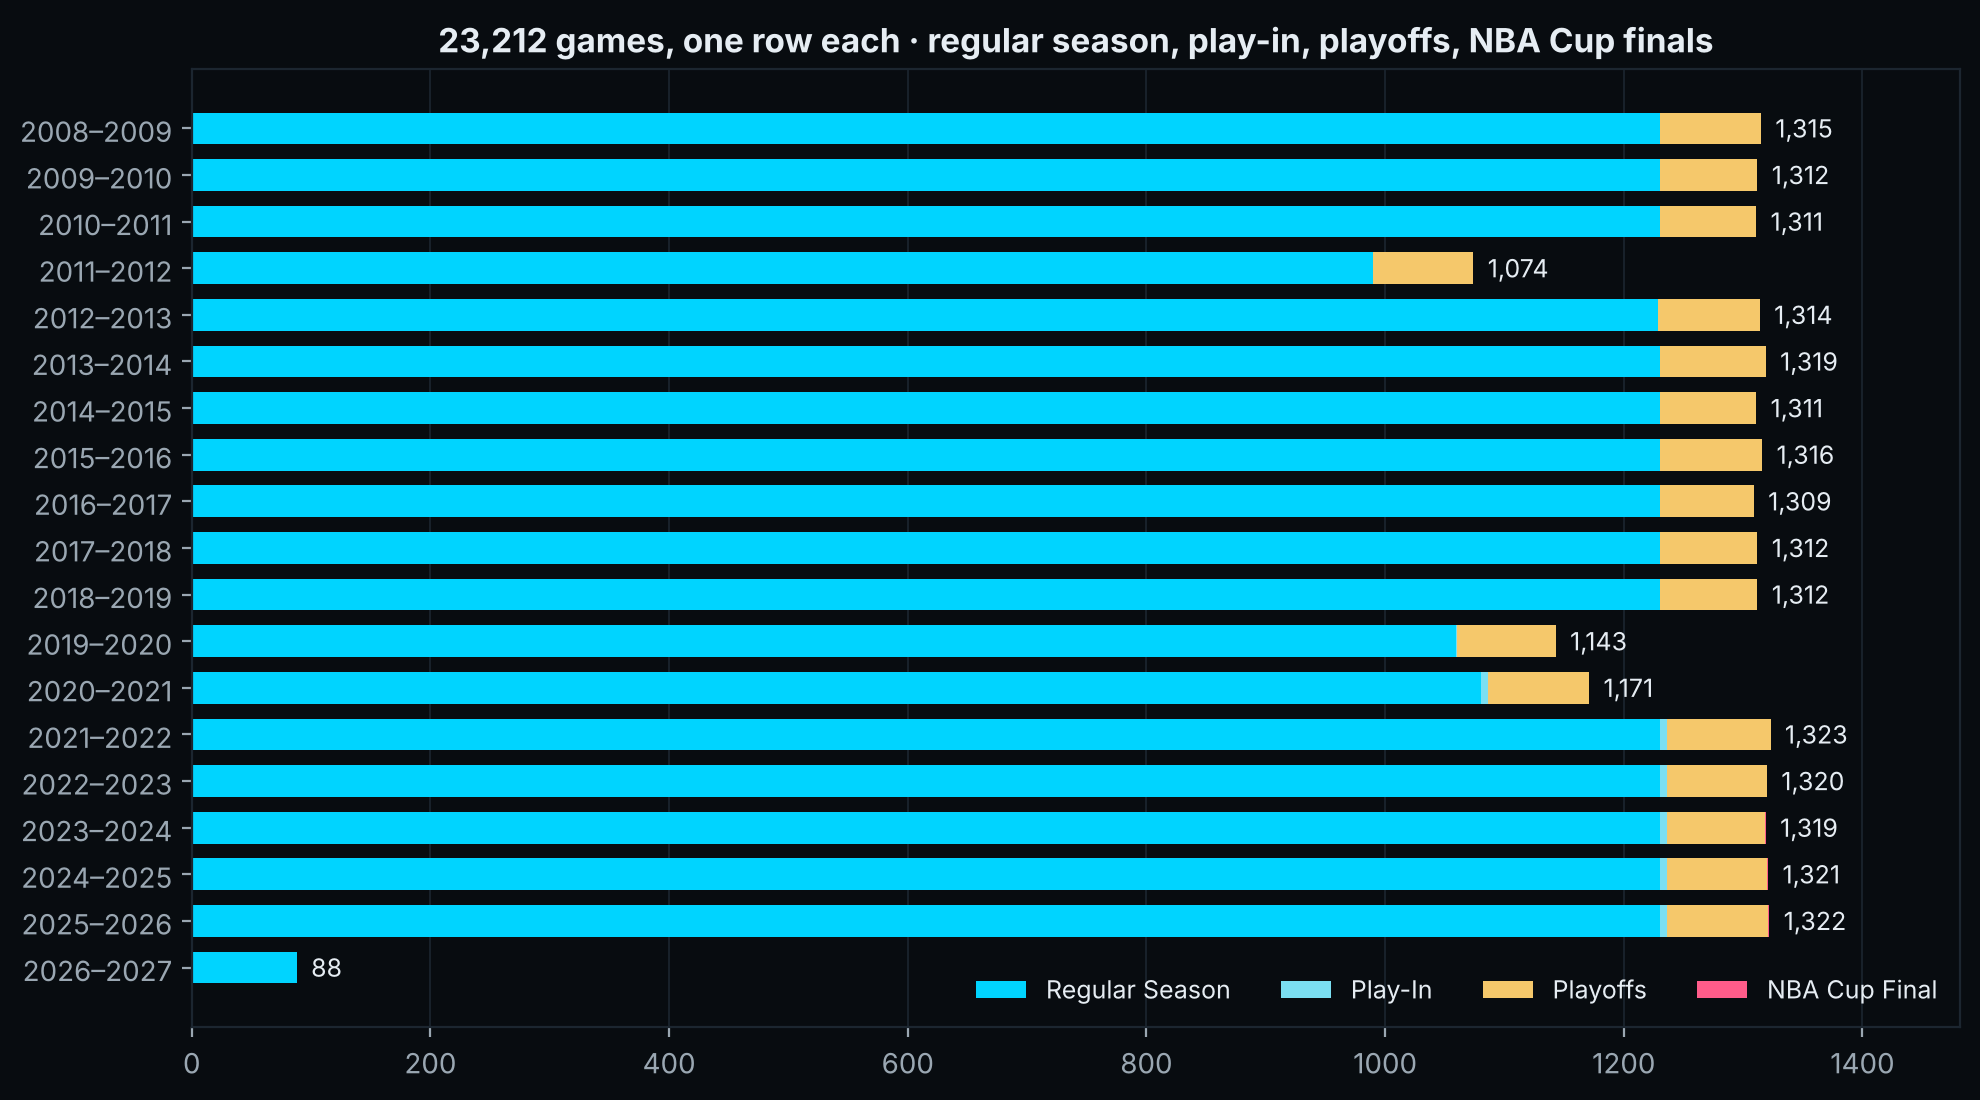

In [6]:
st = pd.crosstab(F["Season"], F["Stage"]).reindex(columns=["Regular Season", "Play-In", "Playoffs", "NBA Cup Final"], fill_value=0)
fig, ax = plt.subplots(figsize=(10, 5.6))
left = np.zeros(len(st))
colors = {"Regular Season": CYAN, "Play-In": "#7bdff2", "Playoffs": AMBER, "NBA Cup Final": "#ff5c8a"}
for stage in st.columns:
    ax.barh(range(len(st)), st[stage], left=left, color=colors[stage], height=0.68, label=stage, zorder=2)
    left += st[stage].to_numpy()
for i, total in enumerate(left):
    ax.text(total + 12, i, f"{int(total):,}", va="center", fontsize=9, color=FG)
ax.set_yticks(range(len(st)), [s.replace("/", "–") for s in st.index])
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlim(0, left.max() * 1.12)
ax.legend(loc="lower right", ncol=4, fontsize=9)
ax.set_title(f"{len(F):,} games, one row each · regular season, play-in, playoffs, NBA Cup finals")
plt.tight_layout(); plt.show()

## 4 · Who is in the file, and from when

The listing gives the first price of each book; the README gives the share of games covered, season by season,
for every book, market and phase. Recomputed here from the price columns.

PASS  first price, book by book, as listed: Bet365 19 Jan 2009 ... Pinnacle 16 Oct 2018   [Pinnacle 20181016 · Bet365 20090119 · William Hill 20100603 · Bwin 20090129 · Betway 20090129 · Betfair Exchange 20090211 · SBOBET 20110307 · 1xBet 20141028]
PASS  Pinnacle's spread from 30 Jul 2020, SBOBET's moneyline from 22 Apr 2019, 1xBet's 1X2 from 28 Oct 2014, spread and total from 2 Jan 2015, moneyline from 31 Oct 2015   [{'Pinnacle Spread': '20200730', 'SBOBET ML': '20190422', '1xBet 1X2': '20141028', '1xBet Spread': '20150102', '1xBet ML': '20151031'}]
PASS  before 2018-19, each season carries 4 to 7 of the other books (all 7 from 2015-16)   [08-09 4 · 09-10 5 · 10-11 6 · 11-12 6 · 12-13 6 · 13-14 6 · 14-15 6 · 15-16 7 · 16-17 7 · 17-18 7]
PASS  1xBet's spread and total start on the same day
PASS  Closing moneyline: share of games, season by season, as in the README (19 seasons × 8 books)
PASS  Opening moneyline: share of games, season by season, as in the README (19 seasons × 8 books)
P

PASS  Opening spread: share of games, season by season, as in the README (19 seasons × 6 books)
PASS  Opening total: share of games, season by season, as in the README (19 seasons × 6 books)


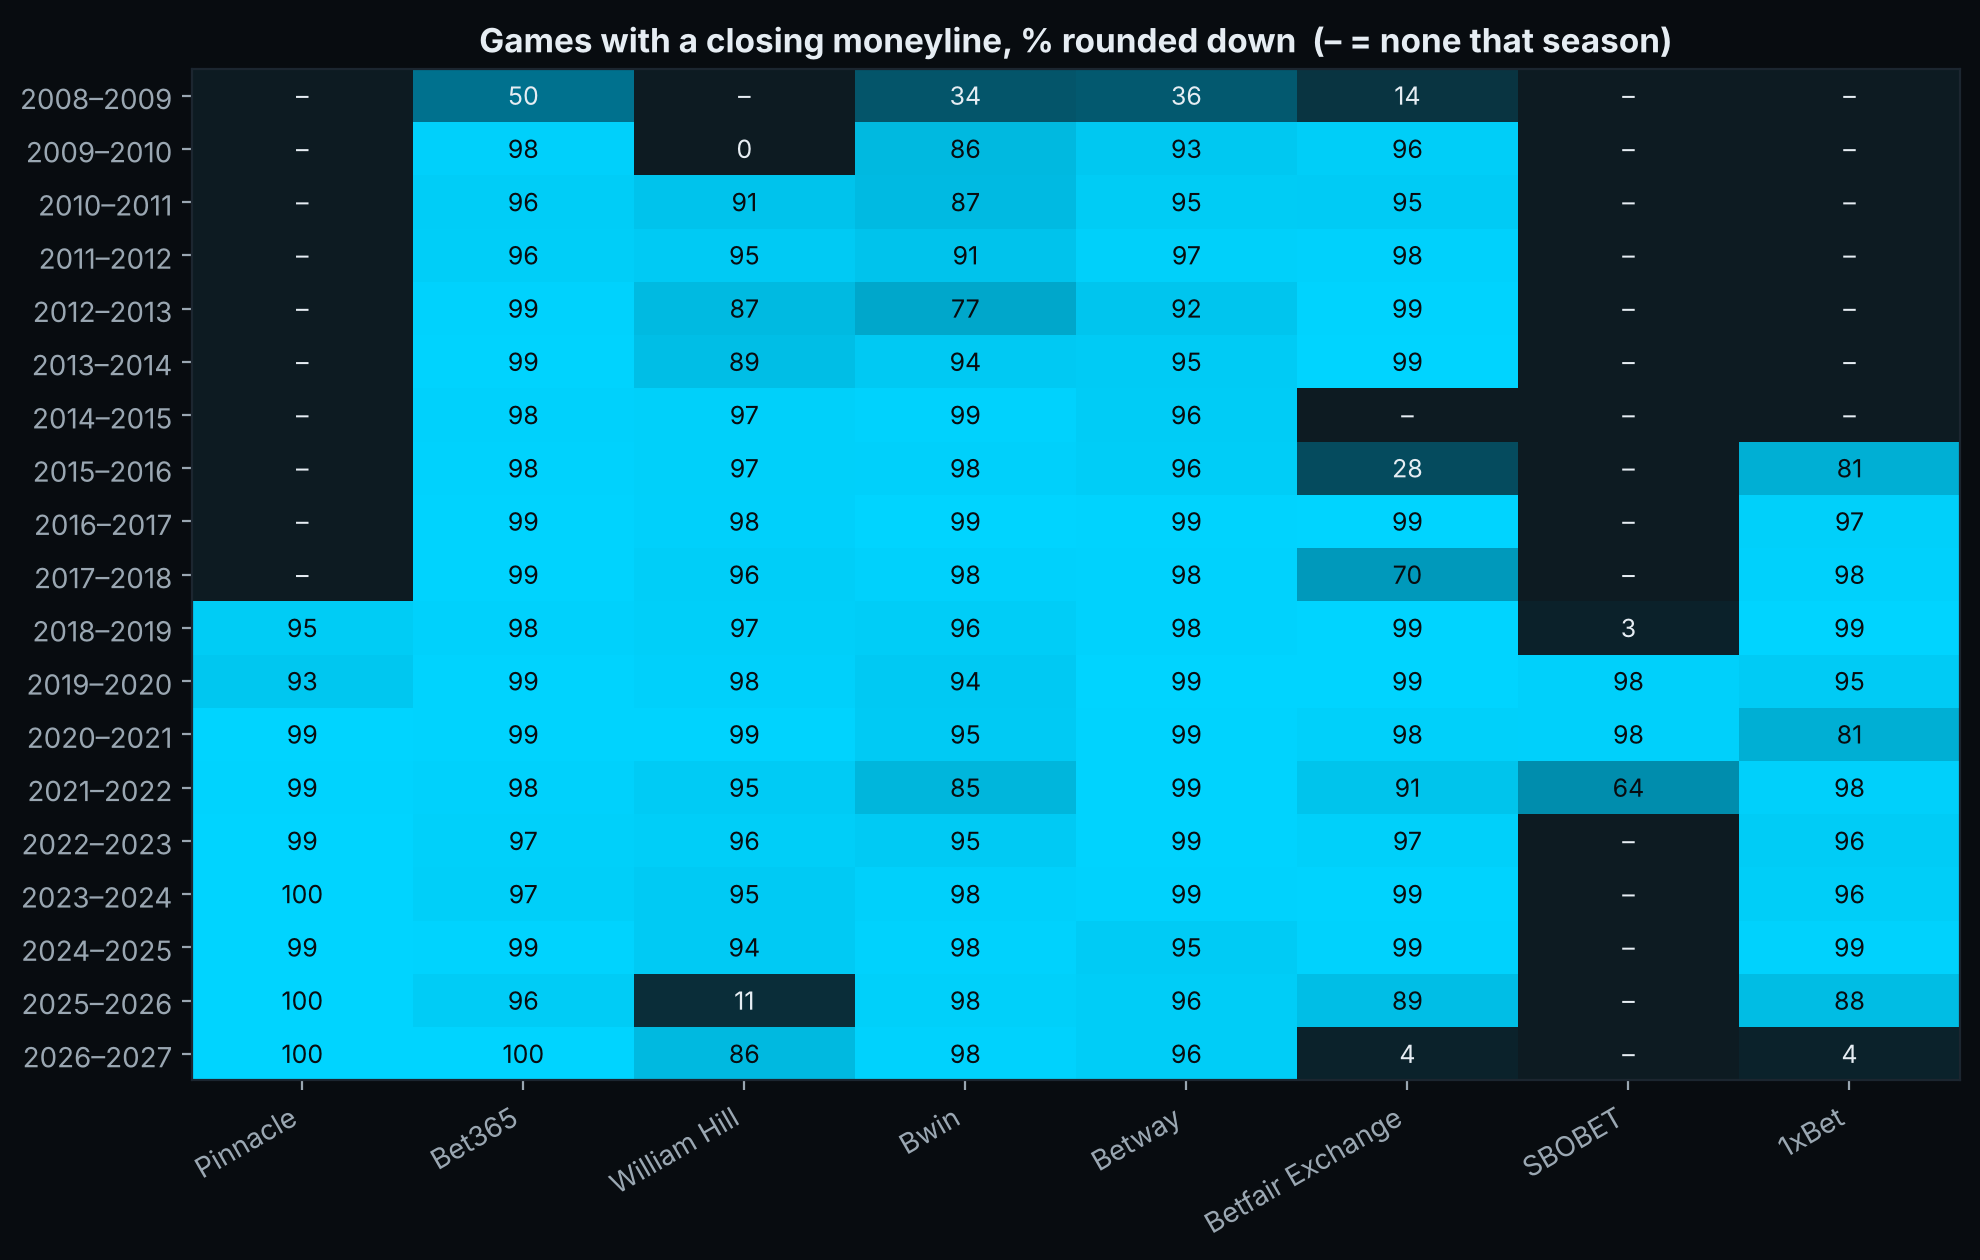

In [7]:
def first_day(book, market=""):
    cols = [c for c in PRICES if c.startswith(f"{book}_{market}")]
    has = F[cols].notna().any(axis=1)
    return F.loc[has, "Game_ID"].str[:8].min()

got = {b: first_day(b) for b in BOOKS}
check("first price, book by book, as listed: Bet365 19 Jan 2009 ... Pinnacle 16 Oct 2018", got == CLAIMS["first_price"],
      " · ".join(f"{NAME.get(b, b)} {d}" for b, d in got.items()))
got_m = {k: first_day(*k.split()) for k in CLAIMS["first_price_market"]}
check("Pinnacle's spread from 30 Jul 2020, SBOBET's moneyline from 22 Apr 2019, 1xBet's 1X2 from 28 Oct 2014, "
      "spread and total from 2 Jan 2015, moneyline from 31 Oct 2015", got_m == CLAIMS["first_price_market"], f"{got_m}")
pre18 = F[F["Season"] < "2018/2019"]
nbk = {s: sum(x[[c for c in PRICES if c.startswith(b + "_")]].notna().any().any() for b in BOOKS) for s, x in pre18.groupby("Season")}
check("before 2018-19, each season carries 4 to 7 of the other books (all 7 from 2015-16)", nbk == CLAIMS["books_before_pinnacle"],
      " · ".join(f"{s[2:4]}-{s[-2:]} {n}" for s, n in nbk.items()))
check("1xBet's spread and total start on the same day",
      first_day("1xBet", "Spread") == first_day("1xBet", "Total") == CLAIMS["first_price_market"]["1xBet Spread"])

for (field, title), expected in CLAIMS["coverage"].items():
    books = list(next(iter(expected.values())).keys())
    got = {s: {b: share(int(x[f"{b}_{field}"].notna().sum()), len(x)) for b in books} for s, x in F.groupby("Season")}
    diff = [f"{s} {NAME.get(b, b)} {got[s][b]} vs {expected.get(s, {}).get(b)}" for s in got for b in books if got[s][b] != expected.get(s, {}).get(b)]
    check(f"{title}: share of games, season by season, as in the README ({len(got)} seasons × {len(books)} books)",
          not diff and set(got) == set(expected), ", ".join(diff[:4]))

cov = pd.DataFrame({b: {s: x[f"{b}_ML_Home_Close"].notna().mean() * 100 for s, x in F.groupby("Season")} for b in BOOKS})
cmap = LinearSegmentedColormap.from_list("cyan", ["#0d1b22", "#00708c", CYAN])
fig, ax = plt.subplots(figsize=(10, 6.4))
ax.imshow(cov.to_numpy(), aspect="auto", cmap=cmap, vmin=0, vmax=100)
ax.set_xticks(range(len(BOOKS)), [NAME.get(b, b) for b in BOOKS], rotation=30, ha="right")
ax.set_yticks(range(len(cov)), [s.replace("/", "–") for s in cov.index])
ax.grid(False)
for i in range(cov.shape[0]):
    for j in range(cov.shape[1]):
        v = cov.iat[i, j]
        ax.text(j, i, "–" if v == 0 else str(int(v)), ha="center", va="center", fontsize=9, color=BG if v > 60 else FG)
ax.set_title("Games with a closing moneyline, % rounded down  (– = none that season)")
plt.tight_layout(); plt.show()

## 5 · Opening, closing, tip-off

The opening price is the first price recorded for the main line, the closing price the last one before tip-off.
The README sets hard limits and gives the median times; all recomputed here.

In [8]:
opens = [c for c in ODDS if c.endswith("_Open_Time")]
closes = [c for c in ODDS if c.endswith("_Close_Time")]
do = pd.concat([minutes_vs_tipoff(c) for c in opens], axis=1)
dc = pd.concat([minutes_vs_tipoff(c) for c in closes], axis=1)
check("no opening price is stamped after the scheduled tip-off", do.max().max() <= 0, f"latest {do.max().max():.0f} min")
check(f"no opening price older than {CLAIMS['oldest_opening_days']} days", -do.min().min() <= CLAIMS["oldest_opening_days"] * 1440,
      f"oldest {-do.min().min() / 1440:.1f} days before")
check(f"every closing price recorded between {CLAIMS['oldest_close_hours']} h before and {CLAIMS['latest_close_minutes']} min after "
      "the scheduled tip-off", -dc.min().min() <= 60 * CLAIMS["oldest_close_hours"] and dc.max().max() <= CLAIMS["latest_close_minutes"],
      f"oldest {-dc.min().min() / 60:.2f} h before, latest {dc.max().max():.1f} min after")
after = sum(int((ts(o) >= ts(o.replace("_Open_", "_Close_"))).sum()) for o in opens)
check("an opening price is always recorded before the closing price of the same book and market", after == 0, f"{after}")

got = {b: {m: ("–" if f"{b}_{m}_Close_Time" not in F else short_age(minutes_vs_tipoff(f"{b}_{m}_Close_Time").median()))
           for m in ("ML", "Spread", "Total", "1X2")} for b in BOOKS}
check("median closing time against the scheduled tip-off, book by book and market by market, as in the README",
      got == CLAIMS["median_close"])
age = {b: round(-minutes_vs_tipoff(f"{b}_ML_Open_Time").median() / 60) for b in BOOKS}
check("median age of the opening moneyline at tip-off, as in the README", age == CLAIMS["median_open_age_h"],
      " · ".join(f"{NAME.get(b, b)} {h} h" for b, h in age.items()))
pin = minutes_vs_tipoff("Pinnacle_ML_Close_Time")
pre = {s: round(-pin[(F["Season"] == s) & (KICK < pd.Timestamp("2020-07-01", tz="UTC"))].median() / 60, 1)
       for s in CLAIMS["pinnacle_close_before_restart_h"]}
post = round(pin[KICK >= RESTART].median())
check("Pinnacle's closing moneyline: a median 5.4 h before tip-off in 2018-19, 5.1 h in 2019-20 before the pause, "
      "9 min after from the restart", pre == CLAIMS["pinnacle_close_before_restart_h"] and post == CLAIMS["pinnacle_close_from_restart_min"],
      " · ".join(f"{s[2:4]}-{s[-2:]} {v} h" for s, v in pre.items()) + f" · from the restart {post} min")

def seconds(book, season=None):
    x = F if season is None else F[F["Season"] == season]
    v = pd.Series(RAW.loc[x.index, [c for c in ODDS if c.startswith(book + "_") and c.endswith("_Time")]].to_numpy().ravel()).dropna()
    return int((~v.str.endswith(":00Z")).sum()), len(v)
sec = {b: seconds(b) for b in BOOKS}
bw, bw_n = seconds("Betway", "2026/2027")
check("times to the minute, except Pinnacle (to the second), 65% of Betway's 2026-27 times and 8 of William Hill's",
      sec["Pinnacle"][0] / sec["Pinnacle"][1] > 0.9 and round(100 * bw / bw_n) == CLAIMS["seconds"]["Betway 2026-27 %"]
      and sec["Betway"][0] == bw and sec["WilliamHill"][0] == CLAIMS["seconds"]["WilliamHill cells"]
      and all(sec[b][0] == 0 for b in ("Bet365", "Bwin", "BetfairExchange", "SBOBET", "1xBet")),
      " · ".join(f"{NAME.get(b, b)} {s:,} of {n:,}" for b, (s, n) in sec.items()))
pd.DataFrame(got).T.rename(index=NAME).rename_axis("Median closing time")

PASS  no opening price is stamped after the scheduled tip-off   [latest -2 min]
PASS  no opening price older than 14 days   [oldest 13.4 days before]
PASS  every closing price recorded between 12 h before and 30 min after the scheduled tip-off   [oldest 12.00 h before, latest 29.6 min after]


PASS  an opening price is always recorded before the closing price of the same book and market   [0]


PASS  median closing time against the scheduled tip-off, book by book and market by market, as in the README
PASS  median age of the opening moneyline at tip-off, as in the README   [Pinnacle 21 h · Bet365 17 h · William Hill 19 h · Bwin 24 h · Betway 20 h · Betfair Exchange 23 h · SBOBET 18 h · 1xBet 27 h]
PASS  Pinnacle's closing moneyline: a median 5.4 h before tip-off in 2018-19, 5.1 h in 2019-20 before the pause, 9 min after from the restart   [18-19 5.4 h · 19-20 5.1 h · from the restart 9 min]


PASS  times to the minute, except Pinnacle (to the second), 65% of Betway's 2026-27 times and 8 of William Hill's   [Pinnacle 54,545 of 56,771 · Bet365 0 of 95,351 · William Hill 8 of 33,655 · Bwin 0 of 125,211 · Betway 354 of 85,406 · Betfair Exchange 0 of 20,856 · SBOBET 0 of 56,666 · 1xBet 0 of 98,538]


,ML,Spread,Total,1X2
Median closing time,,,,
Pinnacle,8 min after,9 min after,8 min after,–
Bet365,45 min before,71 min before,92 min before,–
William Hill,69 min before,–,–,–
Bwin,53 min before,71 min before,65 min before,45 min before
Betway,36 min before,2.1 h before,53 min before,15 min before
Betfair Exchange,4 min before,–,–,–
SBOBET,18 min before,5 min before,12 min before,–
1xBet,27 min before,31 min before,28 min before,28 min before


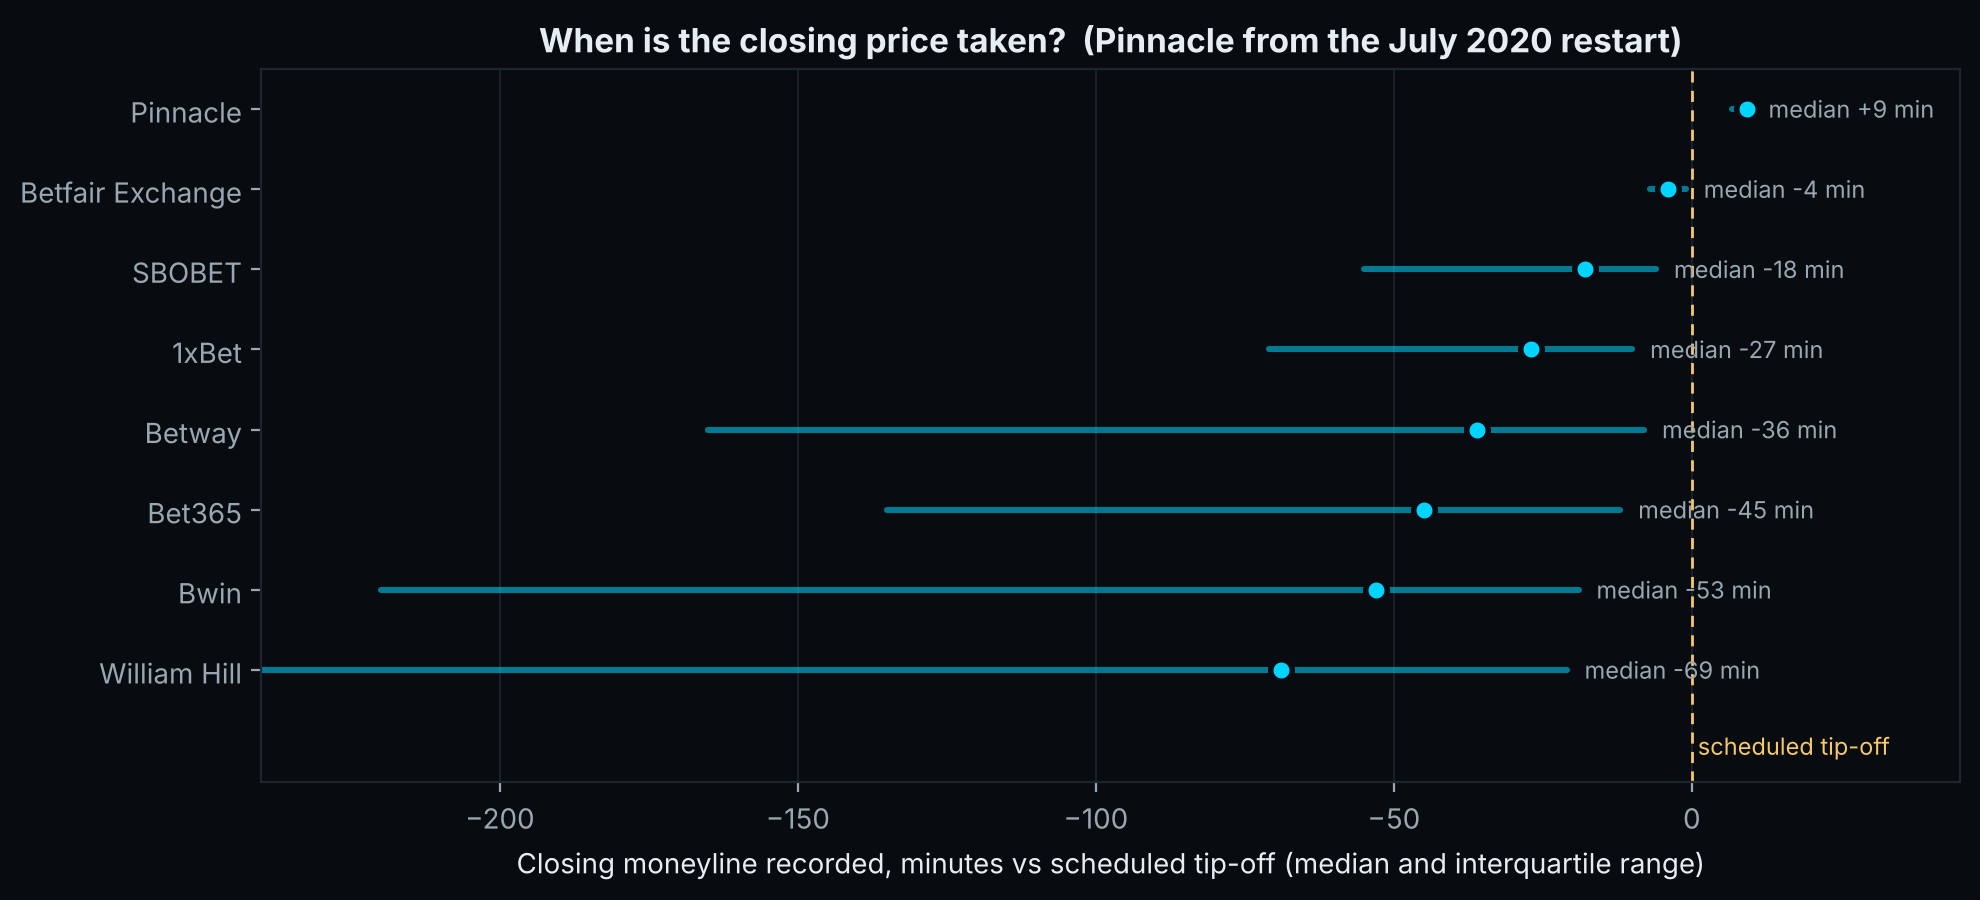

In [9]:
med = {b: minutes_vs_tipoff(f"{b}_ML_Close_Time").dropna() for b in BOOKS}
med["Pinnacle"] = med["Pinnacle"][KICK[med["Pinnacle"].index] >= RESTART]
order = sorted(BOOKS, key=lambda b: med[b].median())
fig, ax = plt.subplots(figsize=(10, 4.6))
for i, b in enumerate(order):
    q1, q2, q3 = np.percentile(med[b], [25, 50, 75])
    ax.plot([q1, q3], [i, i], color=CYAN, linewidth=2.2, alpha=0.55, solid_capstyle="round")
    ax.scatter([q2], [i], s=60, color=CYAN, edgecolor=BG, linewidth=2, zorder=3)
    ax.text(max(q3, q2) + 3, i, f"median {q2:+.0f} min", va="center", fontsize=8.5, color=FG2)
ax.axvline(0, color=AMBER, linewidth=1, linestyle=(0, (4, 3)))
ax.text(1, -0.95, "scheduled tip-off", color=AMBER, fontsize=8.5, va="center")
ax.set_ylim(-1.4, len(order) - 0.5)
ax.set_yticks(range(len(order)), [NAME.get(b, b) for b in order])
ax.set_xlim(-240, 45); ax.grid(axis="y", visible=False)
ax.set_xlabel("Closing moneyline recorded, minutes vs scheduled tip-off (median and interquartile range)")
ax.set_title("When is the closing price taken?  (Pinnacle from the July 2020 restart)")
plt.tight_layout(); plt.show()

## 6 · Are these real market prices?

A real closing line is better informed than the opening one: its implied probabilities should predict the
winner better. Probabilities are de-margined proportionally; lower log-loss is better. Open and close are compared
**within a book**, on the games where the book has both.

In [10]:
home_won = (F["Winner"] == "Home").to_numpy()
rows = []
for b in BOOKS:
    o = F[[f"{b}_ML_Home_Open", f"{b}_ML_Away_Open"]].to_numpy(float)
    c = F[[f"{b}_ML_Home_Close", f"{b}_ML_Away_Close"]].to_numpy(float)
    ok = ~np.isnan(o).any(1) & ~np.isnan(c).any(1)
    def logloss(p):
        p = np.clip(p, 1e-6, 1 - 1e-6)
        return -np.mean(np.where(home_won[ok], np.log(p), np.log(1 - p)))
    rows.append((NAME.get(b, b), int(ok.sum()), logloss(no_vig(o[ok, 0], o[ok, 1])), logloss(no_vig(c[ok, 0], c[ok, 1]))))
LL = pd.DataFrame(rows, columns=["Book", "Games", "Log-loss open", "Log-loss close"]).set_index("Book")
check("the closing moneyline predicts the winner better than the opening one, at every book", (LL["Log-loss close"] < LL["Log-loss open"]).all())
mg = {b: 100 * ((1 / F[[f"{b}_ML_Home_Close", f"{b}_ML_Away_Close"]].dropna()).sum(axis=1) - 1).median() for b in ("BetfairExchange", "Pinnacle")}
check("median closing margin: Betfair Exchange 2.8%, above Pinnacle's 2.6% (consistent with prices net of the exchange's commission)",
      {b: round(v, 1) for b, v in mg.items()} == CLAIMS["margin_close_median"], f"{mg['BetfairExchange']:.2f}% · {mg['Pinnacle']:.2f}%")
LL.style.format({"Games": "{:,}", "Log-loss open": "{:.4f}", "Log-loss close": "{:.4f}"})

PASS  the closing moneyline predicts the winner better than the opening one, at every book
PASS  median closing margin: Betfair Exchange 2.8%, above Pinnacle's 2.6% (consistent with prices net of the exchange's commission)   [2.82% · 2.65%]


,Games,Log-loss open,Log-loss close
Book,,,
Pinnacle,"10,159",0.6048,0.5995
Bet365,"18,573",0.6035,0.5984
William Hill,"14,837",0.6079,0.6020
Bwin,"17,877",0.6029,0.5966
Betway,"17,215",0.6050,0.5996
Betfair Exchange,"1,848",0.5855,0.5788
SBOBET,"2,936",0.6244,0.6209
1xBet,"12,185",0.6102,0.6004


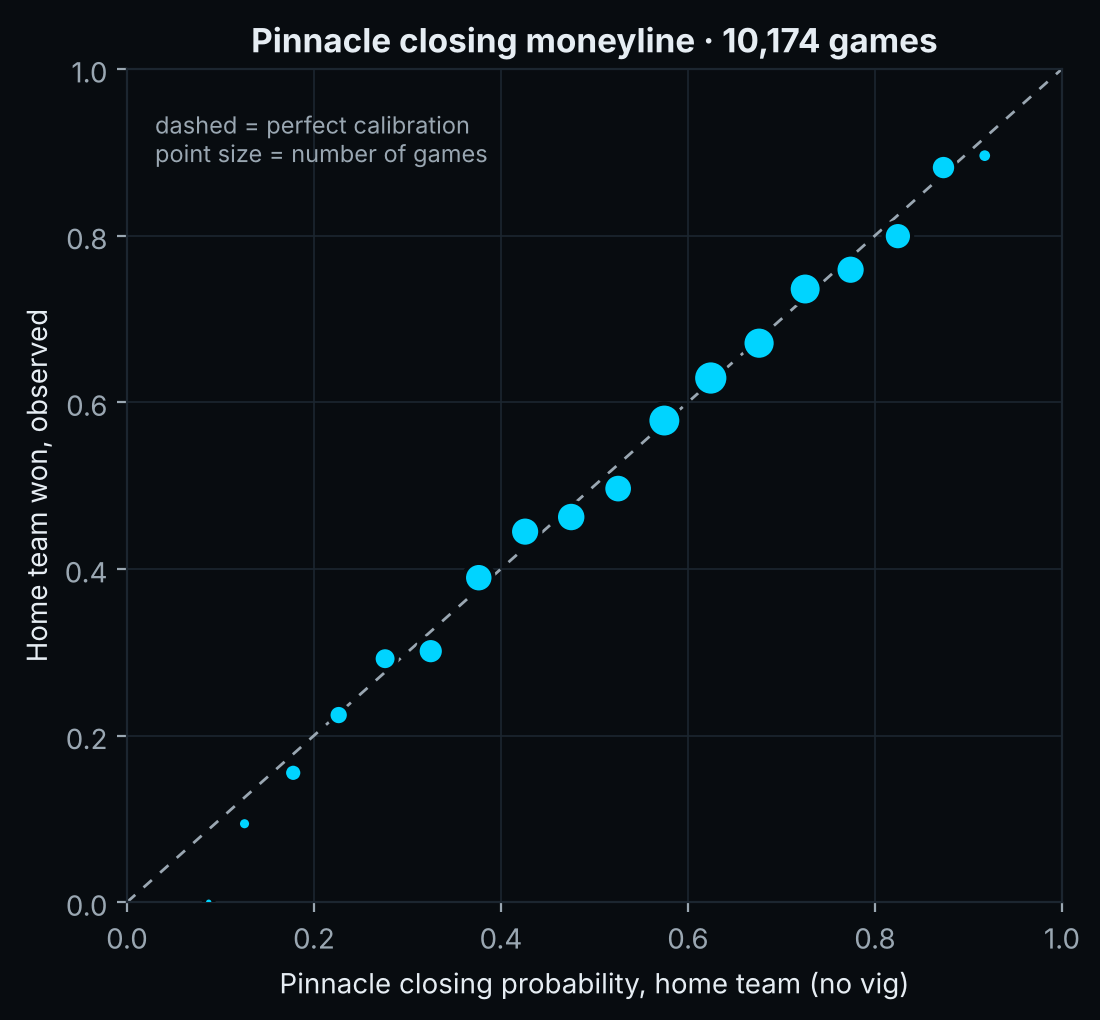

In [11]:
# Pinnacle closing moneyline: predicted probability of the home team vs observed frequency
c = F[["Pinnacle_ML_Home_Close", "Pinnacle_ML_Away_Close"]].to_numpy(float)
ok = ~np.isnan(c).any(1)
cal = pd.DataFrame({"p": no_vig(c[ok, 0], c[ok, 1]), "hit": home_won[ok]})
cal["bin"] = pd.cut(cal["p"], np.arange(0, 1.0001, 0.05))
cb = cal.groupby("bin", observed=True).agg(p=("p", "mean"), freq=("hit", "mean"), n=("hit", "size"))
cb = cb[cb["n"] >= 40]
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.plot([0, 1], [0, 1], color=FG2, linewidth=1, linestyle=(0, (4, 4)))
ax.scatter(cb["p"], cb["freq"], s=np.clip(cb["n"] / 6, 12, 180), color=CYAN, edgecolor=BG, linewidth=1.5, zorder=3)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("Pinnacle closing probability, home team (no vig)"); ax.set_ylabel("Home team won, observed")
ax.set_title(f"Pinnacle closing moneyline · {ok.sum():,} games")
ax.text(0.03, 0.95, "dashed = perfect calibration\npoint size = number of games", fontsize=8.5, color=FG2, va="top")
plt.tight_layout(); plt.show()

## 7 · The games on the listing's images

The eight images of the Gumroad listing are drawn from the file. Their prices, times, scores and figures, recomputed.

In [12]:
G = F.set_index("Game_ID")
R = RAW.set_index("Game_ID")
# image 1: 2021 NBA Finals, home team's closing moneyline at the 8 books
IMG1 = {"20210706_MIL_PHX": "1.4785 1.47 1.5 1.55 1.47 1.49 1.46 1.51", "20210708_MIL_PHX": "1.5376 1.52 1.54 1.53 1.53 1.54 1.51 1.55",
        "20210711_PHX_MIL": "1.5 1.5 1.5 1.53 1.5 1.51 1.42 1.53", "20210714_PHX_MIL": "1.5319 1.5 1.52 1.5 1.5 1.51 1.44 1.51",
        "20210720_PHX_MIL": "1.5525 1.54 1.54 1.53 1.53 1.55 1.57 1.56"}
got = {g: " ".join(R.loc[g, f"{b}_ML_Home_Close"] for b in BOOKS) for g in IMG1}
check("image 1: the 2021 Finals, games 1-4 and 6, home closing moneyline at all 8 books", got == IMG1)
# image 2: 2026 NBA Finals, game 1, closing prices
r = R.loc["20260603_NYK_SAS"]
img2 = {"Pinnacle": ("2.67", "1.5348", "-5", "1.9259", "217.5"), "Bet365": ("2.65", "1.5", "-4.5", "1.87", "217.5"),
        "Bwin": ("2.55", "1.53", "-4.5", "1.87", "217.5")}
ok2 = all((r[f"{b}_ML_Away_Close"], r[f"{b}_ML_Home_Close"], r[f"{b}_Spread_Home_Line_Close"], r[f"{b}_Spread_Home_Close"],
           r[f"{b}_Total_Line_Close"]) == v for b, v in img2.items())
ok2 &= (r["WilliamHill_ML_Away_Close"], r["WilliamHill_ML_Home_Close"], r["Betway_ML_Away_Close"], r["Betway_ML_Home_Close"]) == ("2.6", "1.5", "2.6", "1.53")
ok2 &= (r["Bwin_1X2_Home_Close"], r["Bwin_1X2_Draw_Close"], r["Bwin_1X2_Away_Close"]) == ("1.55", "12.5", "2.6")
ok2 &= (r["Away_Score"], r["Home_Score"]) == ("105", "95")
check("image 2: Knicks at Spurs, 3 Jun 2026, closing prices at 5 books, 105-95", ok2)
# image 3: Raptors at Wizards, 23 Oct 2026, away moneyline, open and close with their times
r = R.loc["20261023_TOR_WAS"]
img3 = {"Pinnacle": ("2.49", "2026-10-22T06:37:41Z", "3.68", "2026-10-23T22:59:21Z"), "Bet365": ("2.45", "2026-10-22T08:32:00Z", "3.65", "2026-10-23T22:46:00Z"),
        "WilliamHill": ("2.38", "2026-10-22T05:17:00Z", "3.6", "2026-10-23T16:47:00Z"), "Bwin": ("2.5", "2026-10-22T12:11:00Z", "3.6", "2026-10-23T13:56:00Z"),
        "Betway": ("2.75", "2026-10-23T03:04:00Z", "3.5", "2026-10-23T22:59:00Z")}
check("image 3: Raptors at Wizards, 23 Oct 2026, 112-102: opening and closing prices with their times",
      all((r[f"{b}_ML_Home_Open"], r[f"{b}_ML_Open_Time"], r[f"{b}_ML_Home_Close"], r[f"{b}_ML_Close_Time"]) == v for b, v in img3.items())
      and (r["Away_Score"], r["Home_Score"]) == ("112", "102"))
# image 4: 9 Feb 2026, totals: Pinnacle open, Pinnacle close, Bet365 close, Bwin close, final points
IMG4 = {"20260209_UTA_MIA": "244.5 234.5 235.5 235.5 226", "20260209_CLE_DEN": "234 243.5 242 242.5 236", "20260209_MEM_GSW": "226 219.5 218.5 218.5 227",
        "20260209_CHI_BKN": "223.5 218.5 218 218.5 238", "20260209_SAC_NOP": "233.5 229.5 229 228.5 214", "20260209_ATL_MIN": "236 239.5 239 238.5 254",
        "20260209_OKC_LAL": "220 223 221.5 222.5 229"}
got = {g: " ".join(R.loc[g, c] for c in ("Pinnacle_Total_Line_Open", "Pinnacle_Total_Line_Close", "Bet365_Total_Line_Close",
                                          "Bwin_Total_Line_Close", "Total_Score")) for g in IMG4}
check("image 4: 9 Feb 2026, the total from Pinnacle's open to the close, and the final points", got == IMG4)
# image 5: the 1X2 in five overtime games of 2025-26 (Bwin home / draw / away, 1xBet draw)
IMG5 = {"20260227_CLE_DET": "1.3 14.5 3.6 16 119 122", "20260305_GSW_HOU": "1.25 15 4.1 17 115 113", "20260312_WAS_ORL": "1.1 23 6.5 22 131 136",
        "20260314_DEN_LAL": "2 14.5 1.83 16 125 127", "20260325_ATL_DET": "1.7 12.5 2.25 10.5 130 129"}
got = {g: " ".join(R.loc[g, c] for c in ("Bwin_1X2_Home_Close", "Bwin_1X2_Draw_Close", "Bwin_1X2_Away_Close", "1xBet_1X2_Draw_Close",
                                          "Away_Score", "Home_Score")) for g in IMG5}
check("image 5: five overtime games, the 1X2 at Bwin and 1xBet's draw, closing prices, final scores",
      got == IMG5 and (G.loc[list(IMG5), "Match_Ending"] == "Overtime").all())
# image 6: 12 Apr 2026, home closing moneyline, Pinnacle and Betfair Exchange, with their times
IMG6 = {"20260412_CHI_DAL": "1.5291 2026-04-13T00:39:33Z 1.48 2026-04-13T00:22:00Z", "20260412_GSW_LAC": "1.6061 2026-04-13T00:39:58Z 1.6 2026-04-13T00:22:00Z",
        "20260412_NOP_MIN": "1.6061 2026-04-13T00:35:26Z 1.58 2026-04-13T00:22:00Z", "20260412_PHX_OKC": "1.3546 2026-04-13T00:39:02Z 1.35 2026-04-13T00:22:00Z",
        "20260412_DEN_SAS": "1.2222 2026-04-13T00:39:23Z 1.25 2026-04-13T00:22:00Z"}
got = {g: " ".join(R.loc[g, c] for c in ("Pinnacle_ML_Home_Close", "Pinnacle_ML_Close_Time", "BetfairExchange_ML_Home_Close",
                                          "BetfairExchange_ML_Close_Time")) for g in IMG6}
check("image 6: 12 Apr 2026, Pinnacle and Betfair Exchange at the close, with their times", got == IMG6)
# image 7: share of all games with a closing moneyline, and in 2025-26
IMG7 = {"Pinnacle": (43.8, 100.0), "Bet365": (95.8, 96.4), "WilliamHill": (79.8, 11.2), "Bwin": (90.5, 98.0), "Betway": (93.9, 96.8),
        "BetfairExchange": (81.5, 89.3), "SBOBET": (13.7, 0.0), "1xBet": (57.5, 88.4)}
IMG7_SEASONS = {"Pinnacle": ("2018/2019", "2026/2027"), "Bet365": ("2008/2009", "2026/2027"), "WilliamHill": ("2009/2010", "2026/2027"),
                "Bwin": ("2008/2009", "2026/2027"), "Betway": ("2008/2009", "2026/2027"), "BetfairExchange": ("2008/2009", "2026/2027"),
                "SBOBET": ("2018/2019", "2021/2022"), "1xBet": ("2015/2016", "2026/2027")}
y = F["Season"] == "2025/2026"
got = {b: (round(100 * F[f"{b}_ML_Home_Close"].notna().mean(), 1), round(100 * F.loc[y, f"{b}_ML_Home_Close"].notna().mean(), 1)) for b in BOOKS}
seas = {b: (F.loc[F[f"{b}_ML_Home_Close"].notna(), "Season"].min(), F.loc[F[f"{b}_ML_Home_Close"].notna(), "Season"].max()) for b in BOOKS}
check("image 7: moneyline seasons, share of games with a closing moneyline, all games and 2025-26", got == IMG7 and seas == IMG7_SEASONS,
      " · ".join(f"{NAME.get(b, b)} {v[0]}%" for b, v in got.items()))
# image 8: the file in figures
check("image 8: 23,212 games · 19 seasons · 8 books · 1,203,088 prices · 182 columns",
      (len(F), F["Season"].nunique(), len(BOOKS), len(cells), F.shape[1]) == (23_212, 19, 8, 1_203_088, 182))

PASS  image 1: the 2021 Finals, games 1-4 and 6, home closing moneyline at all 8 books
PASS  image 2: Knicks at Spurs, 3 Jun 2026, closing prices at 5 books, 105-95
PASS  image 3: Raptors at Wizards, 23 Oct 2026, 112-102: opening and closing prices with their times
PASS  image 4: 9 Feb 2026, the total from Pinnacle's open to the close, and the final points
PASS  image 5: five overtime games, the 1X2 at Bwin and 1xBet's draw, closing prices, final scores
PASS  image 6: 12 Apr 2026, Pinnacle and Betfair Exchange at the close, with their times


PASS  image 7: moneyline seasons, share of games with a closing moneyline, all games and 2025-26   [Pinnacle 43.8% · Bet365 95.8% · William Hill 79.8% · Bwin 90.5% · Betway 93.9% · Betfair Exchange 81.5% · SBOBET 13.7% · 1xBet 57.5%]
PASS  image 8: 23,212 games · 19 seasons · 8 books · 1,203,088 prices · 182 columns


## 8 · Said plainly, checked

The limits the listing and the README state up front, recomputed.

In [13]:
pin_cols = [c for c in PRICES if c.startswith("Pinnacle_")]
pre_pin = F["Game_ID"].str[:8] < CLAIMS["first_price"]["Pinnacle"]
check("no Pinnacle price before 16 Oct 2018, no Pinnacle spread before the 30 Jul 2020 restart",
      not F.loc[pre_pin, pin_cols].notna().any().any()
      and not F.loc[KICK < RESTART, [c for c in pin_cols if "_Spread_" in c]].notna().any().any())
wh = [c for c in PRICES if c.startswith("WilliamHill_")]
y = F["Season"] == "2025/2026"
wh_days = F.loc[y & F[wh].notna().any(axis=1), "Game_ID"].str[:8]
check("William Hill: absent from the start of 2025-26 to 31 Mar 2026, back from 1 Apr 2026", wh_days.min() == CLAIMS["william_hill_back"],
      f"first 2025-26 price {wh_days.min()}")
bf = [c for c in PRICES if c.startswith("BetfairExchange_")]
check("Betfair Exchange: missing in 2014-15", not F.loc[F["Season"] == "2014/2015", bf].notna().any().any())
z = F["Season"] == "2026/2027"
n_bf = int(F.loc[z, bf].notna().any(axis=1).sum()); n_1x = int(F.loc[z, [c for c in PRICES if c.startswith("1xBet_")]].notna().any(axis=1).sum())
check("2026-27 so far: Betfair Exchange and 1xBet on 4 of the 88 games each",
      n_bf == n_1x == CLAIMS["betfair_1xbet_games_2026_27"], f"{n_bf} and {n_1x}")
def season_span(book, market):
    s = F.loc[F[[c for c in PRICES if c.startswith(f"{book}_{market}_")]].notna().any(axis=1), "Season"]
    return (s.min(), s.max())
sb = {m: season_span("SBOBET", m) for m in ("Spread", "Total", "ML")}
check("SBOBET: spread and total from 2010-11 to 2021-22, moneyline from 2018-19 (22 Apr 2019) to 2021-22", sb == CLAIMS["sbobet_seasons"], f"{sb}")
first_1x2 = {b: F.loc[F[f"{b}_1X2_Home_Close"].notna() | F[f"{b}_1X2_Home_Open"].notna(), "Season"].min() for b in ("Bwin", "1xBet", "Betway")}
check("1X2 (regular time): Bwin from 2013-14, 1xBet from 2014-15, Betway from 2016-17", first_1x2 == CLAIMS["first_1x2_season"], f"{first_1x2}")
bw = CLAIMS["betway"]
def days(market):
    return F.loc[F[[c for c in PRICES if c.startswith(f"Betway_{market}_")]].notna().any(axis=1), "Game_ID"].str[:8]
sp_d, to_d, x_d = days("Spread"), days("Total"), days("1X2")
ok_bw = (sp_d.min() == to_d.min() == bw["spread_total_from"]
         and not sp_d.between(*bw["no_spread"]).any() and not pd.concat([sp_d, to_d]).between(*bw["neither"]).any()
         and (F.loc[F["Season"] == "2026/2027", ["Betway_Spread_Home_Close", "Betway_Total_Over_Close"]].notna().all(axis=1).mean() > 0.95))
runs = []                                           # stretches of 1X2 prices, broken by any gap longer than an off-season
for d in sorted(set(x_d)):
    if runs and (pd.Timestamp(d) - pd.Timestamp(runs[-1][1])).days <= 200:
        runs[-1] = (runs[-1][0], d)
    else:
        runs.append((d, d))
ok_x = runs == bw["x12_runs"]
n_x = int((F.loc[F["Season"] == "2026/2027", ["Betway_1X2_Home_Close", "Betway_1X2_Home_Open"]].notna().any(axis=1)).sum())
check("Betway: spread and total from 31 Mar 2011; no spread from 2016-17 to 2023-24, neither from 7 Dec 2024 to the end of 2025-26; "
      "1X2 from 2016-17 to 6 Feb 2022, 7 Dec 2024 to 11 Dec 2025, then 35 games of 2026-27 (20-24 Oct)",
      ok_bw and ok_x and n_x == bw["x12_games_2026_27"], f"1X2 {runs}, {n_x} games in 2026-27")
early = F["Season"] <= "2013/2014"
bsp = {s: int(100 * x["Bwin_Spread_Home_Open"].notna().mean()) for s, x in F[early].groupby("Season")}
bto = {s: 100 * x["Bwin_Total_Over_Open"].notna().mean() for s, x in F[early].groupby("Season")}
check("Bwin's opening spread in 3-7% of games, opening total in under 5%, 2008-09 to 2013-14",
      (min(bsp.values()), max(bsp.values())) == CLAIMS["bwin_thin_openings"]["spread"] and max(bto.values()) < CLAIMS["bwin_thin_openings"]["total_under"],
      f"spread {min(bsp.values())}-{max(bsp.values())}% · total at most {max(bto.values()):.1f}%")
mid = F["Season"].between("2015/2016", "2025/2026")
sp = {s: int(100 * x["Bet365_Spread_Home_Open"].notna().mean()) for s, x in F[mid].groupby("Season")}
to = {s: 100 * x["Bet365_Total_Over_Open"].notna().mean() for s, x in F[mid].groupby("Season")}
lo, hi = CLAIMS["bet365_thin_openings"]["spread"]
check("Bet365's opening spread in 5-29% of games, opening total in under 6%, 2015-16 to 2025-26",
      (min(sp.values()), max(sp.values())) == (lo, hi) and max(to.values()) < CLAIMS["bet365_thin_openings"]["total_under"],
      f"spread {min(sp.values())}-{max(sp.values())}% · total at most {max(to.values()):.1f}%")
ko = F["Game_ID"].str[:8].isin(CLAIMS["nba_cup_knockout_dates"])
others = [c for c in PRICES if not c.startswith("Pinnacle_")]
check("the 21 NBA Cup knockout games of 2023-24 to 2025-26 (quarter-finals, semi-finals, finals) carry Pinnacle prices only",
      ko.sum() == CLAIMS["nba_cup_knockout_games"] and not F.loc[ko, others].notna().any().any()
      and F.loc[ko, pin_cols].notna().any(axis=1).all() and (F.loc[ko, "Stage"] == "NBA Cup Final").sum() == 3, f"{ko.sum()} games")
check("the NBA Cup quarter-finals and semi-finals count in the regular season, the finals do not",
      (F.loc[ko, "Stage"] == "Regular Season").sum() == CLAIMS["nba_cup_rounds_in_regular_season"]
      and set(F.loc[ko, "Stage"]) == {"Regular Season", "NBA Cup Final"})

PASS  no Pinnacle price before 16 Oct 2018, no Pinnacle spread before the 30 Jul 2020 restart
PASS  William Hill: absent from the start of 2025-26 to 31 Mar 2026, back from 1 Apr 2026   [first 2025-26 price 20260401]
PASS  Betfair Exchange: missing in 2014-15
PASS  2026-27 so far: Betfair Exchange and 1xBet on 4 of the 88 games each   [4 and 4]
PASS  SBOBET: spread and total from 2010-11 to 2021-22, moneyline from 2018-19 (22 Apr 2019) to 2021-22   [{'Spread': ('2010/2011', '2021/2022'), 'Total': ('2010/2011', '2021/2022'), 'ML': ('2018/2019', '2021/2022')}]
PASS  1X2 (regular time): Bwin from 2013-14, 1xBet from 2014-15, Betway from 2016-17   [{'Bwin': '2013/2014', '1xBet': '2014/2015', 'Betway': '2016/2017'}]
PASS  Betway: spread and total from 31 Mar 2011; no spread from 2016-17 to 2023-24, neither from 7 Dec 2024 to the end of 2025-26; 1X2 from 2016-17 to 6 Feb 2022, 7 Dec 2024 to 11 Dec 2025, then 35 games of 2026-27 (20-24 Oct)   [1X2 [('20161025', '20220206'), ('20241207', '2025

## 9 · Summary

In [14]:
summary = pd.DataFrame(RESULTS, columns=["Claim", "Pass", "Detail"])
print(f"{summary['Pass'].sum()} / {len(summary)} claims verified")
summary.assign(Result=summary["Pass"].map({True: "PASS", False: "FAIL"}))[["Result", "Claim", "Detail"]].style.hide(axis="index")

68 / 68 claims verified


Result,Claim,Detail
PASS,"23,212 games, Game_ID unique","23,212"
PASS,"182 columns: 14 for the game, then the books",182
PASS,"8 books, in this order: Pinnacle, Bet365, William Hill, Bwin, Betway, Betfair Exchange, SBOBET, 1xBet","Pinnacle, Bet365, WilliamHill, Bwin, Betway, BetfairExchange, SBOBET, 1xBet"
PASS,"for each book, its opening columns come first, then its closing columns",
PASS,"columns per book: 22, 6 for William Hill and Betfair Exchange, 30 with the 1X2",Pinnacle 22 · Bet365 22 · William Hill 6 · Bwin 30 · Betway 30 · Betfair Exchange 6 · SBOBET 22 · 1xBet 30
PASS,"markets per book, as listed (William Hill and Betfair Exchange: moneyline only)",
PASS,"1,203,088 prices","1,203,088"
PASS,"every price is a decimal price of at least 1.01, with up to 4 decimals","lowest 1.01, highest 76.0"
PASS,every price comes with the time it was recorded,0 without a time
PASS,"every time is ISO 8601 in UTC, with the T and the Z","595,666 cells"


---

Everything above ran on the file a buyer downloads. The README in the ZIP holds the full column dictionary, the
coverage of every book season by season, how each price was checked, and every known limitation.

👉 🏀 **[→ Get the full dataset on Gumroad](https://sportsdataolivier.gumroad.com/l/oeuoto?utm_source=github&utm_medium=notebook&utm_campaign=nba_world&utm_content=notebook_bottom)** · also on [Whop](https://whop.com/oliviersportsdata/nba-opening-closing-odds-pinnacle-7-world-books-2008-2026/?utm_source=github&utm_medium=notebook&utm_campaign=nba_world&utm_content=whop_bottom) 👈

Games after 31 October 2026: the **[NBA World Books monthly updates](https://sportsdataolivier.gumroad.com/l/konvk?utm_source=github&utm_medium=notebook&utm_campaign=nba_world&utm_content=notebook_monthly)** (also on [Whop](https://whop.com/oliviersportsdata/nba-opening-closing-odds-monthly-updates-world-books/?utm_source=github&utm_medium=notebook&utm_campaign=nba_world&utm_content=whop_monthly)) add each month's games, same 182 columns.

A question before buying: contact@oliviersportsdata.com

*Olivier Sports Data — From Chicken Area 🐔*